
# Experiment 2 (Revised) — Calibrated Neural Shared/Private Capacity Competition

## Why this version is different

The previous neural experiment mixed together two questions:

1. how difficult the shared/private computations actually are for a neural network;
2. whether a fixed capacity budget makes specialization preferable.

That made the empirical \(\tau\) manipulation ambiguous.

This notebook separates the two.

### Stage A — calibrate the route-specific learning curves

Measure directly:

\[
L_S(s;\varepsilon)
\]

for a shared circuit of width \(s\), and

\[
L_P(p;\tau)
\]

for a private circuit of width \(p\).

This tells us what "capacity" means for the actual neural architecture.

### Stage B — solve the neural allocation problem

For a total budget \(N\), enumerate allocations

\[
s + r p = N,
\]

where \(r\) languages receive private circuits and the other \(K-r\) languages use the shared circuit.

For every allocation, train the neural circuits and measure validation loss.

The question is then:

> Does the empirically best neural allocation move in the directions predicted by the theoretical capacity-competition model?

---

# The controlled task

We use an invariant parity task:

\[
z\in\{-1,+1\}^d,\qquad
y=\prod_{j=1}^{d}z_j.
\]

Every language receives the same underlying semantic content \(z\), so the target is invariant.

### Shared route: controlled distortion

The shared circuit receives an erased version of \(z\):

\[
\tilde z_j =
\begin{cases}
z_j & \text{with probability }1-e,\\
0 & \text{with probability }e.
\end{cases}
\]

For parity, if any bit is erased then the label is unrecoverable. Therefore the Bayes MSE floor is exactly

\[
\boxed{
\varepsilon_{\mathrm{Bayes}}
=
1-(1-e)^d.
}
\]

This makes \(\varepsilon\) an actual information-loss manipulation rather than an arbitrary change to a language's lookup table.

### Private route: controlled shortcut

The private circuit receives the full semantic vector \(z\) plus a language-local cue \(c\):

\[
c=
\begin{cases}
y & \text{with probability }q,\\
-y & \text{otherwise.}
\end{cases}
\]

A cue-only predictor has Bayes MSE

\[
4q(1-q).
\]

The cue therefore gives a genuinely cheap solution when \(q\) is high, while \(q=0.5\) makes it useless.

We use

\[
\boxed{
\tau_{\mathrm{proxy}}=(2q-1)^2
}
\]

only as an operational shortcut-strength proxy. It is not claimed to be identical to the abstract \(\tau\) in the theory.

The important empirical object is the **measured private learning curve**, not the proxy itself.


In [1]:

import math
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

torch.set_num_threads(max(1, min(8, torch.get_num_threads())))


Device: cuda



## 1. Configuration

The development run is intentionally modest.

For the final experiment, increase both the width/budget grid and the number of random seeds.



In [2]:

@dataclass
class Config:
    # Languages
    K: int = 4

    # Invariant task
    d_semantic: int = 4

    # Data
    n_train_per_language: int = 1200
    n_val_per_language: int = 800
    batch_size: int = 256

    # Training
    epochs: int = 80
    lr: float = 1e-3
    weight_decay: float = 1e-4

    # Route calibration widths
    calibration_widths: tuple = (1, 2, 4, 8, 12, 16, 24, 32)

    # Total capacity budgets.
    # For K=4 these must be compatible with r*p + s.
    budgets: tuple = (8, 12, 16, 20, 24, 32)

    # Shortcut conditions
    q_low: float = 0.50
    q_high: float = 0.95

    # Shared-space distortion conditions
    erase_low: float = 0.05
    erase_high: float = 0.20

    # Development seeds
    seeds: tuple = (0,)

    verbose: bool = True


CFG = Config()
print(asdict(CFG))


{'K': 4, 'd_semantic': 4, 'n_train_per_language': 1200, 'n_val_per_language': 800, 'batch_size': 256, 'epochs': 80, 'lr': 0.001, 'weight_decay': 0.0001, 'calibration_widths': (1, 2, 4, 8, 12, 16, 24, 32), 'budgets': (8, 12, 16, 20, 24, 32), 'q_low': 0.5, 'q_high': 0.95, 'erase_low': 0.05, 'erase_high': 0.2, 'seeds': (0,), 'verbose': True}



## 2. Data generation

Each language gets its own equally sized dataset.

The underlying \(z\) and target \(y\) are language-independent.

The language identity matters only because a language can be assigned a private circuit.

This is important: the experiment tests **allocation of computation**, not whether the task itself is different between languages.


In [3]:

def make_language_dataset(
    n,
    d,
    q_shortcut,
    erase_prob,
    seed
):
    rng = np.random.default_rng(seed)

    z = rng.choice([-1.0, 1.0], size=(n, d)).astype(np.float32)
    y = np.prod(z, axis=1).astype(np.float32)

    # Language-local shortcut cue.
    cue = np.where(
        rng.random(n) < q_shortcut,
        y,
        -y
    ).astype(np.float32)

    # Shared interface: erase semantic bits and remove the shortcut.
    keep = (rng.random((n, d)) >= erase_prob).astype(np.float32)
    shared_z = z * keep
    shared_x = shared_z

    # Private interface: full semantic content + shortcut.
    private_x = np.concatenate(
        [z, cue[:, None]],
        axis=1
    )

    return (
        torch.from_numpy(shared_x),
        torch.from_numpy(private_x),
        torch.from_numpy(y[:, None])
    )


def make_language_loaders(cfg, q_shortcut, erase_prob, seed):
    train_loaders = []
    val_loaders = []

    for L in range(cfg.K):
        # Different examples per language, same distribution.
        tr = make_language_dataset(
            cfg.n_train_per_language,
            cfg.d_semantic,
            q_shortcut,
            erase_prob,
            seed + 1000 * L
        )
        va = make_language_dataset(
            cfg.n_val_per_language,
            cfg.d_semantic,
            q_shortcut,
            erase_prob,
            seed + 1000 * L + 500000
        )

        train_loaders.append(
            DataLoader(
                TensorDataset(*tr),
                batch_size=cfg.batch_size,
                shuffle=True
            )
        )
        val_loaders.append(
            DataLoader(
                TensorDataset(*va),
                batch_size=cfg.batch_size,
                shuffle=False
            )
        )

    return train_loaders, val_loaders


def epsilon_bayes(erase_prob, d):
    return 1.0 - (1.0 - erase_prob) ** d


def tau_proxy(q):
    return (2.0 * q - 1.0) ** 2


conditions = {
    "low_tau_low_eps": {
        "q": CFG.q_low,
        "erase": CFG.erase_low,
    },
    "high_tau_low_eps": {
        "q": CFG.q_high,
        "erase": CFG.erase_low,
    },
    "low_tau_high_eps": {
        "q": CFG.q_low,
        "erase": CFG.erase_high,
    },
    "high_tau_high_eps": {
        "q": CFG.q_high,
        "erase": CFG.erase_high,
    },
}

condition_df = pd.DataFrame([
    {
        "condition": name,
        "q": spec["q"],
        "erase_prob": spec["erase"],
        "tau_proxy": tau_proxy(spec["q"]),
        "epsilon_bayes": epsilon_bayes(
            spec["erase"], CFG.d_semantic
        ),
        "cue_only_mse": 4 * spec["q"] * (1 - spec["q"]),
    }
    for name, spec in conditions.items()
])

condition_df


,condition,q,erase_prob,tau_proxy,epsilon_bayes,cue_only_mse
0,low_tau_low_eps,0.50,0.05,0.00,0.185494,1.00
1,high_tau_low_eps,0.95,0.05,0.81,0.185494,0.19
2,low_tau_high_eps,0.50,0.20,0.00,0.590400,1.00
3,high_tau_high_eps,0.95,0.20,0.81,0.590400,0.19



## 3. Neural circuit

We intentionally use the same small MLP family for both routes so that the calibration tells us how width maps to task performance.

The shared route sees \(d\) semantic inputs.

The private route sees \(d+1\) inputs: the same semantic content plus the shortcut cue.

The key point is that **private-route capacity is not assumed to be cheaper**. We measure its learning curve and let the data show whether the shortcut actually creates the predicted reduction in required capacity.


In [4]:

class MLP(nn.Module):
    def __init__(self, input_dim, width):
        super().__init__()

        self.width = width

        if width < 1:
            raise ValueError("Width must be >= 1.")

        self.net = nn.Sequential(
            nn.Linear(input_dim, width),
            nn.Tanh(),
            nn.Linear(width, 1)
        )

    def forward(self, x):
        return self.net(x)


def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


def seed_everything(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)



# 4. Stage A — route-specific calibration

This is the most important new component.

Before asking the neural system to choose between routes, measure:

\[
L_S(s;\varepsilon)
\]

and

\[
L_P(p;\tau).
\]

For the shared route we expect the large-width curve to approach the Bayes floor:

\[
L_S(s)\rightarrow\varepsilon_{\mathrm{Bayes}}.
\]

For the private route we expect high shortcut strength \(q\) to reduce the width needed for a target loss.

We therefore report:

- validation loss vs. width;
- parameter count vs. width;
- width required to reach fixed loss thresholds;
- empirical shortcut-capacity discount.


In [5]:

def train_single_route(
    input_dim,
    width,
    train_loader,
    val_loader,
    epochs,
    lr,
    weight_decay,
    seed,
    route="shared",
):
    """
    Train one route from loaders whose batches contain:
        shared_x, private_x, y

    route="shared" selects shared_x.
    route="private" selects private_x.
    """
    if route not in {"shared", "private"}:
        raise ValueError("route must be 'shared' or 'private'")

    seed_everything(seed)

    model = MLP(input_dim, width).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    best_val = np.inf

    for epoch in range(epochs):
        model.train()

        for shared_x, private_x, y in train_loader:
            x = shared_x if route == "shared" else private_x

            x = x.to(DEVICE)
            y = y.to(DEVICE)

            pred = model(x)
            loss = ((pred - y) ** 2).mean()

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            vals = []
            for shared_x, private_x, y in val_loader:
                x = shared_x if route == "shared" else private_x

                x = x.to(DEVICE)
                y = y.to(DEVICE)

                pred = model(x)
                vals.append(((pred - y) ** 2).mean().item())

        best_val = min(best_val, float(np.mean(vals)))

    return model, best_val


def calibrate_routes(cfg, condition_name, spec, seed):
    # Use one representative language for calibration because all languages
    # are identically distributed at this stage.
    train_loaders, val_loaders = make_language_loaders(
        cfg,
        spec["q"],
        spec["erase"],
        seed
    )

    shared_train = train_loaders[0]
    shared_val = val_loaders[0]

    private_train = train_loaders[0]
    private_val = val_loaders[0]

    rows = []

    for width in cfg.calibration_widths:
        if cfg.verbose:
            print(
                f"[calibration] {condition_name:>18s} "
                f"width={width:>2d} seed={seed}"
            )

        shared_model, shared_loss = train_single_route(
            cfg.d_semantic,
            width,
            shared_train,
            shared_val,
            cfg.epochs,
            cfg.lr,
            cfg.weight_decay,
            seed,
            route="shared"
        )

        private_model, private_loss = train_single_route(
            cfg.d_semantic + 1,
            width,
            private_train,
            private_val,
            cfg.epochs,
            cfg.lr,
            cfg.weight_decay,
            seed + 12345,
            route="private"
        )

        rows.append({
            "condition": condition_name,
            "route": "shared",
            "width": width,
            "parameters": count_parameters(shared_model),
            "val_loss": shared_loss,
            "tau_proxy": tau_proxy(spec["q"]),
            "epsilon_bayes": epsilon_bayes(
                spec["erase"],
                cfg.d_semantic
            ),
            "seed": seed,
        })

        rows.append({
            "condition": condition_name,
            "route": "private",
            "width": width,
            "parameters": count_parameters(private_model),
            "val_loss": private_loss,
            "tau_proxy": tau_proxy(spec["q"]),
            "epsilon_bayes": epsilon_bayes(
                spec["erase"],
                cfg.d_semantic
            ),
            "seed": seed,
        })

    return pd.DataFrame(rows)



## 5. Run route calibration

Run this before the allocation sweep.

The result we want to see is:

### Shared routes

As width grows,

\[
L_S(s)
\]

falls but approaches a nonzero floor controlled by \(\varepsilon\).

### Private routes

When \(q\) is high,

\[
L_P(p;q_{\mathrm{high}})
\]

should reach a given target loss at smaller \(p\) than

\[
L_P(p;q_{\mathrm{low}}).
\]

If that does not happen, we should **not** proceed to the allocation experiment: the chosen synthetic task has failed to operationalize the theoretical ingredients.


In [6]:

calibration_runs = []

for condition_name, spec in conditions.items():
    calibration_runs.append(
        calibrate_routes(
            CFG,
            condition_name,
            spec,
            seed=CFG.seeds[0]
        )
    )

calibration = pd.concat(
    calibration_runs,
    ignore_index=True
)

calibration.head()


[calibration]    low_tau_low_eps width= 1 seed=0
[calibration]    low_tau_low_eps width= 2 seed=0
[calibration]    low_tau_low_eps width= 4 seed=0
[calibration]    low_tau_low_eps width= 8 seed=0
[calibration]    low_tau_low_eps width=12 seed=0
[calibration]    low_tau_low_eps width=16 seed=0
[calibration]    low_tau_low_eps width=24 seed=0
[calibration]    low_tau_low_eps width=32 seed=0
[calibration]   high_tau_low_eps width= 1 seed=0
[calibration]   high_tau_low_eps width= 2 seed=0
[calibration]   high_tau_low_eps width= 4 seed=0
[calibration]   high_tau_low_eps width= 8 seed=0
[calibration]   high_tau_low_eps width=12 seed=0
[calibration]   high_tau_low_eps width=16 seed=0
[calibration]   high_tau_low_eps width=24 seed=0
[calibration]   high_tau_low_eps width=32 seed=0
[calibration]   low_tau_high_eps width= 1 seed=0
[calibration]   low_tau_high_eps width= 2 seed=0
[calibration]   low_tau_high_eps width= 4 seed=0
[calibration]   low_tau_high_eps width= 8 seed=0
[calibration]   low_

,condition,route,width,parameters,val_loss,tau_proxy,epsilon_bayes,seed
0,low_tau_low_eps,shared,1,7,1.013847,0.0,0.185494,0
1,low_tau_low_eps,private,1,8,1.006277,0.0,0.185494,0
2,low_tau_low_eps,shared,2,13,1.017832,0.0,0.185494,0
3,low_tau_low_eps,private,2,15,1.012142,0.0,0.185494,0
4,low_tau_low_eps,shared,4,25,1.001982,0.0,0.185494,0


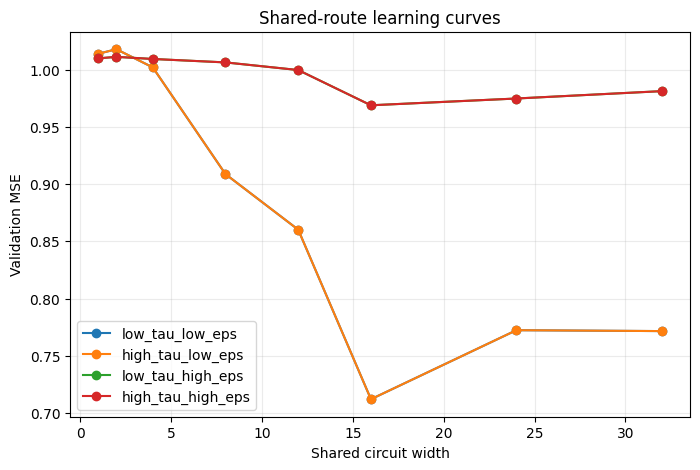

In [7]:

plt.figure(figsize=(8, 5))

for condition_name in conditions:
    sub = calibration[
        (calibration["condition"] == condition_name) &
        (calibration["route"] == "shared")
    ].sort_values("width")

    plt.plot(
        sub["width"],
        sub["val_loss"],
        marker="o",
        label=condition_name
    )

plt.xlabel("Shared circuit width")
plt.ylabel("Validation MSE")
plt.title("Shared-route learning curves")
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()


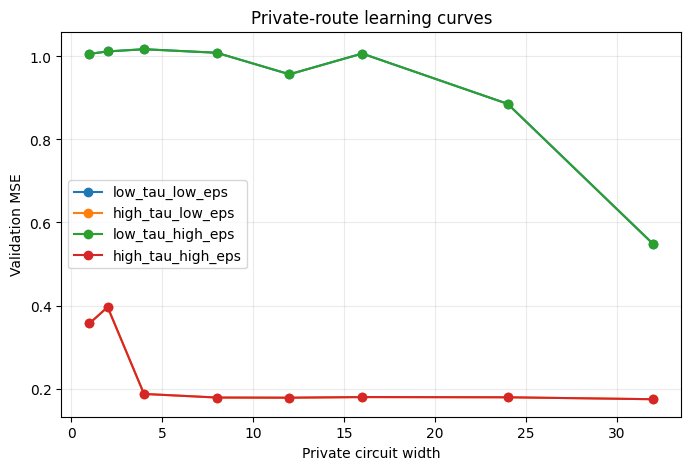

In [8]:

plt.figure(figsize=(8, 5))

for condition_name in conditions:
    sub = calibration[
        (calibration["condition"] == condition_name) &
        (calibration["route"] == "private")
    ].sort_values("width")

    plt.plot(
        sub["width"],
        sub["val_loss"],
        marker="o",
        label=condition_name
    )

plt.xlabel("Private circuit width")
plt.ylabel("Validation MSE")
plt.title("Private-route learning curves")
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()



## 6. Empirical shortcut-capacity discount

Rather than assuming that \(q\) corresponds to a particular theoretical \(\tau\), estimate an operational capacity discount.

For a target validation loss \(\ell_0\), define

\[
w_{\mathrm{req}}(q,\ell_0)
=
\min\{w:L_P(w;q)\le\ell_0\}.
\]

Then define

\[
\boxed{
\hat\tau_{\mathrm{cap}}
=
1-
\frac{
w_{\mathrm{req}}(q_{\mathrm{high}},\ell_0)
}{
w_{\mathrm{req}}(q_{\mathrm{low}},\ell_0)
}.
}
\]

This is deliberately a **neural capacity proxy** for shortcut richness.

It asks the directly measurable question:

> How much private capacity does the shortcut actually save?


In [9]:

def required_width(calibration_df, condition_name, route, target_loss):
    sub = calibration_df[
        (calibration_df["condition"] == condition_name) &
        (calibration_df["route"] == route)
    ].sort_values("width")

    ok = sub[sub["val_loss"] <= target_loss]

    if len(ok) == 0:
        return np.inf

    return int(ok["width"].iloc[0])


# Choose a threshold in the useful range after inspecting calibration.
TARGET_LOSS = 0.25

# For a clean tau comparison, compare low/high tau at the same epsilon.
rows = []

for eps_label in ["low", "high"]:
    cond_low = f"low_tau_{eps_label}_eps"
    cond_high = f"high_tau_{eps_label}_eps"

    w_low = required_width(
        calibration,
        cond_low,
        "private",
        TARGET_LOSS
    )
    w_high = required_width(
        calibration,
        cond_high,
        "private",
        TARGET_LOSS
    )

    tau_cap = (
        1.0 - w_high / w_low
        if np.isfinite(w_low) and np.isfinite(w_high) and w_low > 0
        else np.nan
    )

    rows.append({
        "epsilon_condition": eps_label,
        "width_low_tau": w_low,
        "width_high_tau": w_high,
        "tau_capacity_proxy": tau_cap,
    })

shortcut_calibration = pd.DataFrame(rows)
shortcut_calibration


,epsilon_condition,width_low_tau,width_high_tau,tau_capacity_proxy
0,low,inf,4,NaN
1,high,inf,4,NaN



### Calibration gate

We should proceed only if both of these are true:

1. increasing \(e\) raises the observed asymptotic shared loss;
2. increasing \(q\) lowers the private width required for a fixed target loss.

If either fails, the correct response is to redesign the synthetic task, not to tune the allocation experiment until it gives the desired curve.



# 7. Stage B — neural capacity allocation

Now we introduce the actual sharing/separation competition.

For a fixed budget \(N\), an allocation with \(r\) private languages uses

\[
\boxed{s+r p=N}
\]

where:

- \(s\) = width of the single shared circuit;
- \(p\) = width of each of the \(r\) private circuits;
- \(K-r\) languages remain on the shared circuit.

All feasible \((r,s,p)\) allocations are enumerated.

This gives the neural counterpart of the theoretical optimization.

There is **no learned route gate** in this stage. The allocation itself is controlled so that we can ask a clean question:

> Which architecture achieves the lowest loss after training?

That avoids conflating allocation with optimization of a soft routing variable.


In [10]:

class AllocationModel(nn.Module):
    """
    One shared circuit plus r private circuits.
    Private circuits are assigned to the first r languages.
    """
    def __init__(self, K, d, shared_width, private_width, r_private):
        super().__init__()

        self.K = K
        self.r_private = r_private
        self.shared_width = shared_width
        self.private_width = private_width

        self.shared = MLP(d, shared_width)

        self.private = nn.ModuleList([
            MLP(d + 1, private_width)
            for _ in range(r_private)
        ]) if r_private > 0 else nn.ModuleList([])

    def forward_shared(self, x):
        return self.shared(x)

    def forward_private(self, x, local_index):
        return self.private[local_index](x)


In [11]:

def feasible_allocations(total_budget, K):
    """
    Enumerate integer allocations s + r*p = N,
    where r is the number of private languages.
    """
    out = []

    for r in range(K + 1):
        if r == 0:
            if total_budget >= 1:
                out.append({
                    "r_private": 0,
                    "shared_width": total_budget,
                    "private_width": 0,
                })
            continue

        for p in range(1, total_budget // r + 1):
            s = total_budget - r * p

            if s >= 1:
                out.append({
                    "r_private": r,
                    "shared_width": s,
                    "private_width": p,
                })

    return out


def seed_model(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)



### Balanced training

Each language has its own equally sized dataset.

The shared circuit sees the examples from the languages assigned to it, while each private circuit sees one language.

This preserves the computational sharing structure without giving the shared route a larger per-language sample set.


In [12]:

def train_allocation(
    cfg,
    spec,
    allocation,
    seed
):
    seed_model(seed)

    train_loaders, val_loaders = make_language_loaders(
        cfg,
        spec["q"],
        spec["erase"],
        seed
    )

    r = allocation["r_private"]
    s = allocation["shared_width"]
    p = allocation["private_width"]

    model = AllocationModel(
        K=cfg.K,
        d=cfg.d_semantic,
        shared_width=s,
        private_width=p if r > 0 else 1,
        r_private=r
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=cfg.lr,
        weight_decay=cfg.weight_decay
    )

    # Iterate for the same number of optimizer steps per epoch.
    steps = max(len(loader) for loader in train_loaders)

    for epoch in range(cfg.epochs):
        model.train()

        iterators = [
            iter(loader)
            for loader in train_loaders
        ]

        for _ in range(steps):
            losses = []

            for L in range(cfg.K):
                try:
                    shared_x, private_x, y = next(iterators[L])
                except StopIteration:
                    iterators[L] = iter(train_loaders[L])
                    shared_x, private_x, y = next(iterators[L])

                shared_x = shared_x.to(DEVICE)
                private_x = private_x.to(DEVICE)
                y = y.to(DEVICE)

                if L < r:
                    pred = model.forward_private(
                        private_x,
                        local_index=L
                    )
                else:
                    pred = model.forward_shared(shared_x)

                losses.append(((pred - y) ** 2).mean())

            loss = torch.stack(losses).mean()

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

    # Evaluate every language separately.
    model.eval()

    per_language = []
    route_losses = []

    with torch.no_grad():
        for L in range(cfg.K):
            vals = []

            for shared_x, private_x, y in val_loaders[L]:
                shared_x = shared_x.to(DEVICE)
                private_x = private_x.to(DEVICE)
                y = y.to(DEVICE)

                if L < r:
                    pred = model.forward_private(
                        private_x,
                        local_index=L
                    )
                    route = "private"
                else:
                    pred = model.forward_shared(shared_x)
                    route = "shared"

                vals.append(((pred - y) ** 2).mean().item())

            lang_loss = float(np.mean(vals))

            per_language.append(lang_loss)
            route_losses.append({
                "language": L,
                "route": route,
                "loss": lang_loss,
            })

    result = {
        **allocation,
        "unit_budget": s + r * p,
        "parameter_count": sum(
            param.numel()
            for param in model.parameters()
            if param.requires_grad
        ),
        "val_loss": float(np.mean(per_language)),
        "shared_language_loss": (
            float(np.mean(per_language[r:]))
            if r < cfg.K else np.nan
        ),
        "private_language_loss": (
            float(np.mean(per_language[:r]))
            if r > 0 else np.nan
        ),
        "seed": seed,
    }

    return result, pd.DataFrame(route_losses)



## 8. Allocation sweep

For development, use the default budgets and one seed.

For the paper result, use:

\[
N\in\{8,12,16,20,24,32,40,48,64\}
\]

and at least 3 seeds.

The important output is not absolute MSE.

It is the identity of the **best allocation** at each budget.


In [13]:

def run_allocation_sweep(
    cfg,
    conditions_to_run=None,
    budgets=None,
    seeds=None
):
    if conditions_to_run is None:
        conditions_to_run = list(conditions.keys())

    if budgets is None:
        budgets = cfg.budgets

    if seeds is None:
        seeds = cfg.seeds

    rows = []
    route_rows = []

    for condition_name in conditions_to_run:
        spec = conditions[condition_name]

        for seed in seeds:
            for N in budgets:
                allocations = feasible_allocations(N, cfg.K)

                if cfg.verbose:
                    print(
                        f"\n{condition_name} | N={N} | "
                        f"{len(allocations)} allocations"
                    )

                for allocation in allocations:
                    if cfg.verbose:
                        print(
                            "  ",
                            allocation
                        )

                    result, route_df = train_allocation(
                        cfg,
                        spec,
                        allocation,
                        seed
                    )

                    result.update({
                        "condition": condition_name,
                        "tau_proxy": tau_proxy(spec["q"]),
                        "epsilon_bayes": epsilon_bayes(
                            spec["erase"],
                            cfg.d_semantic
                        )
                    })

                    rows.append(result)

                    route_df["condition"] = condition_name
                    route_df["unit_budget"] = N
                    route_df["r_private"] = allocation["r_private"]
                    route_df["shared_width"] = allocation["shared_width"]
                    route_df["private_width"] = allocation["private_width"]
                    route_df["seed"] = seed
                    route_rows.append(route_df)

    return (
        pd.DataFrame(rows),
        pd.concat(route_rows, ignore_index=True)
    )


In [14]:

RUN_FULL = False

if RUN_FULL:
    budgets_to_run = (8, 12, 16, 20, 24, 32, 40, 48, 64)
    seeds_to_run = (0, 1, 2)
else:
    budgets_to_run = CFG.budgets
    seeds_to_run = CFG.seeds

# Main neural experiment:
# allocation_results, route_results = run_allocation_sweep(
#     CFG,
#     budgets=budgets_to_run,
#     seeds=seeds_to_run
# )

print(
    "Set RUN_FULL=True and uncomment the sweep above "
    "for the full neural experiment."
)


Set RUN_FULL=True and uncomment the sweep above for the full neural experiment.



## 9. Analysis of the neural allocation experiment

For each condition and capacity \(N\), choose the architecture with minimum validation loss.

The core quantity is

\[
\hat r^*(N)
=
\arg\min_r
\hat{\mathcal L}_r(N).
\]

The theory predicts:

\[
\varepsilon\uparrow
\Rightarrow
\hat r^*(N)\text{ becomes larger earlier},
\]

and

\[
\tau\uparrow
\Rightarrow
\hat r^*(N)\text{ becomes larger earlier}.
\]


In [15]:

def best_neural_allocations(allocation_results):
    ordered = allocation_results.sort_values(
        ["condition", "unit_budget", "val_loss"]
    )

    best = (
        ordered
        .groupby(
            ["condition", "unit_budget"],
            as_index=False
        )
        .first()
    )

    return best


# Example analysis after a sweep:
#
# best_alloc = best_neural_allocations(allocation_results)
# best_alloc[[
#     "condition",
#     "unit_budget",
#     "r_private",
#     "shared_width",
#     "private_width",
#     "val_loss"
# ]]


In [16]:

# Example plotting cell to run after the allocation sweep.

# for condition_name in conditions:
#     sub = best_alloc[
#         best_alloc["condition"] == condition_name
#     ].sort_values("unit_budget")
#
#     plt.plot(
#         sub["unit_budget"],
#         sub["r_private"],
#         marker="o",
#         label=condition_name
#     )
#
# plt.xlabel("Total capacity N")
# plt.ylabel("Empirically optimal number of private languages")
# plt.title("Learned specialization vs. capacity")
# plt.legend()
# plt.grid(True, alpha=0.25)
# plt.show()



# 10. The decisive comparisons

The revised experiment should be judged in this order.

### Test 1 — Does \(\varepsilon\) behave correctly?

Compare the shared-route calibration curves.

We need:

\[
e_{\mathrm{high}}>e_{\mathrm{low}}
\]

to produce a higher asymptotic shared loss.

If not, the shared bottleneck is not doing what the theory requires.

### Test 2 — Does the shortcut actually reduce private capacity?

Compare private-route calibration at

\[
q_{\mathrm{low}}
\]

and

\[
q_{\mathrm{high}}.
\]

We need high \(q\) to reach the same loss at smaller width.

If not, the synthetic cue is not a meaningful operationalization of \(\tau\).

### Test 3 — Does capacity induce specialization?

For a fixed \((\tau,\varepsilon)\), examine

\[
\hat r^*(N).
\]

We want a transition toward larger private allocations as \(N\) grows.

### Test 4 — Do the comparative statics survive training?

The strongest neural result is:

\[
\boxed{
N^*_{\mathrm{high}\;\tau}
<
N^*_{\mathrm{low}\;\tau}
}
\]

and

\[
\boxed{
N^*_{\mathrm{high}\;\varepsilon}
<
N^*_{\mathrm{low}\;\varepsilon}.
}
\]

This is the actual hypothesis test for the theory.



# 11. Optional: compare neural thresholds to the calibrated loss model

Once Stage A has been run, we can replace the theoretical scaling assumption with empirical route-specific curves.

For example, fit/interpolate

\[
\widehat L_S(s)
\]

and

\[
\widehat L_P(p;q)
\]

from the calibration data.

Then define an **empirical allocation predictor**

\[
\widehat{\mathcal L}_r^*(N)
\]

using those measured curves, rather than assuming

\[
q(n)=n^{-\beta}.
\]

This gives us a powerful three-way comparison:

1. theoretical power-law prediction;
2. empirically calibrated neural loss prediction;
3. actually trained allocation.

If (2) and (3) agree but (1) is imperfect, the core capacity-competition mechanism survives while the simple power-law approximation can be relaxed.

That would be a much stronger and cleaner result for the eventual paper.



# 12. What we learn from this experiment

The desired outcome is not simply that "bigger networks specialize."

The stronger result is:

> A trainable neural system exhibits the same **capacity-allocation comparative statics** as the theoretical model once the route-specific learning curves are independently calibrated.

The experiment therefore separates three claims that were previously conflated:

\[
\text{shared route has a quality floor}
\]

\[
\text{private route can become cheaper through shortcuts}
\]

\[
\text{a fixed capacity budget makes specialization increasingly worthwhile}.
\]

Only if all three are observed should we move to the PCFG experiment.

The PCFG can then ask whether the same mechanism emerges in a more language-like synthetic environment, and the final real-model experiment can ask whether the resulting representational signature appears in multilingual LMs.
